<a href="https://colab.research.google.com/github/haojin-teng/ps1/blob/main/Problem%20Set%201/Econ_3916_PS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

A family with 2 kids and only father earns. Use trains and spend on education.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [ ]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    # {"Item": ..., "Price_2019": ..., "Price_2024": ..., "weight": ...},
    {"Item": "Rent", "Price_2019": 3200, "Price_2024": 3400, "weight":0.34},
    {"Item": "Foods", "Price_2019": 1200, "Price_2024": 1500, "weight":0.13 },
    {"Item": "Education", "Price_2019": 4000, "Price_2024": 6000, "weight": 0.45},
    {"Item": "Clothese", "Price_2019": 200, "Price_2024": 240, "weight": 0.02},
    {"Item": "Transportation", "Price_2019": 500, "Price_2024": 600, "weight": 0.05},
    {"Item": "Internet", "Price_2019": 50, "Price_2024": 75, "weight":0.01 },

]

In [ ]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

6 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [ ]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    # YOUR CODE HERE
    result = 0
    for item in basket:
      result += item[current_key] / item[base_key]*item["weight"]
    return result*100


print(laspeyres(household_basket, "Price_2019", "Price_2024"))

129.775


In [ ]:
# 1. the unweighted average price change across categories
unave=0
for item in household_basket:
  unave += item["Price_2024"]/item["Price_2019"]/len(household_basket)*100
print(unave)
# 2. your weighted Laspeyres index
print(laspeyres(household_basket, "Price_2019", "Price_2024"))

# 3. the gap between them
print(laspeyres(household_basket, "Price_2019", "Price_2024")-unave)

128.54166666666669
129.775
1.23333333333332


**Why do the two differ, and which would you defend to the client?**

The weight affects the result. The higher the original expense, the greater the impact of its rising price on the final result.
I would defend the Laspeyres index because it reflects an overall rise in prices based on the proportion of baseline expenses.

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [ ]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETG","CUSR0000SEEB","CPIAPPSL"]

def load_fred(series_id):
    """Return one FRED series, from `start` to the latest month, as a Series indexed by date."""

    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    frame = pd.read_csv(url)

    frame.columns = ["date", series_id]
    frame["date"] = pd.to_datetime(frame["date"])

    frame[series_id] = pd.to_numeric(frame[series_id], errors="coerce")

    return frame.set_index("date")[series_id].dropna()

fred_data = {}

for series_id in series_ids:
  fred_data[series_id] = load_fred(series_id).to_frame(name=series_id)

| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
|` CPIAUCSL	`| It is the official CPI the client questions for this family's overall costs |It is average, so it may not match this family's  overall cost|
| `CUSR0000SEHA`	| It tracks monthly rental and shelter market costs which is a stand-in for this family's rent |It is average of the all rent in the US, so it may not match this family's rent in Boston |
| `CUSR0000SAF11	`| It measures price changes for groceries which is a stand-in for this family's food| It is average, so it may not match this family's food cost for 4 people|
| `CUSR0000SETG`	| It measures public transit and train fare fluctuations which is a stand-in for this family's transportation|It includes flight expense, so it may not match this family's transport fees. |
| `CUSR0000SEEB`	| It follows college tuition and childcare fee trends which is a stand-in for this family's tuition fees| It includes all schools, so it may not match this family's expense of individual school.|
| `CPIAPPSL`	| It reflects broad retail prices for clothing and footwear which is a stand-in for this family's clothes| It includes all apparel expenses, so it may not match this family's clothes for children.|


### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [ ]:
rebased = {}
for series_id in series_ids:
  base_2019 = fred_data[series_id].loc[fred_data[series_id].index.year == 2019, series_id].mean()
  rebased[series_id] = fred_data[series_id] / base_2019 * 100


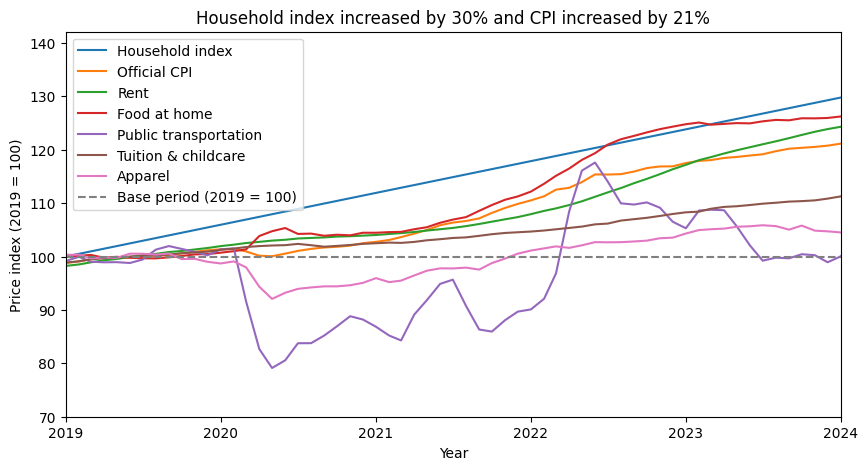

In [ ]:
# One chart: every rebased series, plus your household index
names = {"CPIAUCSL":"Official CPI", "CUSR0000SEHA":"Rent", "CUSR0000SAF11":"Food at home", "CUSR0000SETG":"Public transportation", "CUSR0000SEEB":"Tuition & childcare", "CPIAPPSL":"Apparel"}

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(pd.to_datetime(["2019-01-01", "2024-01-01"]), [100, 129.775], label="Household index")
for series_id, rebased_series in rebased.items():
  	ax.plot(fred_data[series_id].index, rebased_series[series_id],label=names[series_id])
ax.axhline(100, color="gray", linestyle="--", label="Base period (2019 = 100)")
ax.set_xlabel("Year")
ax.set_xlim(left=pd.Timestamp("2019-01-01"),right=pd.Timestamp("2024-01-01"))
ax.set_ylabel("Price index (2019 = 100)")
ax.set_ylim(bottom=70)
ax.set_title("Household index increased by 30% and CPI increased by 21%")
ax.legend()
plt.show()

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [ ]:
# First observation, last observation, frequency and missing months, for every series
for series_id in series_ids:
 print(fred_data[series_id][series_id].asfreq("MS").isna().sum())
 grid = fred_data[series_id][series_id].asfreq("MS")
 print(grid.index.min())
 print(grid.index.max())
 print(grid.loc[grid.isna() == True])


1
1947-01-01 00:00:00
2026-08-01 00:00:00
date
2025-10-01   NaN
Freq: MS, Name: CPIAUCSL, dtype: float64
1
1981-01-01 00:00:00
2026-08-01 00:00:00
date
2025-10-01   NaN
Freq: MS, Name: CUSR0000SEHA, dtype: float64
1
1952-01-01 00:00:00
2026-08-01 00:00:00
date
2025-10-01   NaN
Freq: MS, Name: CUSR0000SAF11, dtype: float64
1
1989-01-01 00:00:00
2026-08-01 00:00:00
date
2025-10-01   NaN
Freq: MS, Name: CUSR0000SETG, dtype: float64
1
1978-01-01 00:00:00
2026-08-01 00:00:00
date
2025-10-01   NaN
Freq: MS, Name: CUSR0000SEEB, dtype: float64
1
1947-01-01 00:00:00
2026-08-01 00:00:00
date
2025-10-01   NaN
Freq: MS, Name: CPIAPPSL, dtype: float64


All six series are missing 2025-10-01.This is because a federal government shutdown.

| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
|CPIAUCSL | 1947-01-01|2026-08-01 | MS|1(2025-10-01) |
|CUSR0000SEHA |1981-01-01 |2026-08-01 |MS |1(2025-10-01) |
|CUSR0000SAF11 |1952-01-01 |2026-08-01 |MS |1(2025-10-01 )|
| CUSR0000SETG|1989-01-01 |2026-08-01 |MS |1(2025-10-01 ) |
|CUSR0000SEEB |1978-01-01 |2026-08-01 |MS |1(2025-10-01 )|
|CPIAPPSL |1947-01-01 |2026-08-01 | MS|1(2025-10-01 ) |

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [ ]:
# Start dates side by side, and the common sample
for series_id in series_ids:
 grid = fred_data[series_id][series_id].asfreq("MS")
 print(series_id, grid.index.min())

print("common sample length", len(fred_data["CUSR0000SETG"]["CUSR0000SETG"].index))
print("longest series it discards", len(fred_data["CPIAPPSL"]["CPIAPPSL"].index)- len(fred_data["CUSR0000SETG"]["CUSR0000SETG"].index))


CPIAUCSL 1947-01-01 00:00:00
CUSR0000SEHA 1981-01-01 00:00:00
CUSR0000SAF11 1952-01-01 00:00:00
CUSR0000SETG 1989-01-01 00:00:00
CUSR0000SEEB 1978-01-01 00:00:00
CPIAPPSL 1947-01-01 00:00:00
common sample length 451
longest series it discards 504


In [ ]:
# Headline comparison: full history vs common sample
common_years = len(fred_data["CUSR0000SETG"]["CUSR0000SETG"].index) / 12
for series_id in series_ids:

  s = fred_data[series_id][series_id]
  print("full history",(s.iloc[-1]/s.iloc[0])**(1/(len(s.index)/12))-1,"common sample", (s.iloc[-1]/s.loc["1989-01-01"])**(1/common_years)-1)



full history 0.03508623678937739 common sample 0.027349790262049867
full history 0.03728421511097002 common sample 0.033464766947941094
full history 0.03176190201015516 common sample 0.026486482640786235
full history 0.023630296310998444 common sample 0.023630296310998444
full history 0.05885860508833951 common sample 0.04831839775137481
full history 0.016059979389641432 common sample 0.003783836691304554


**What restricting to the common sample assumes, and what not restricting assumes:**

Common sample: Discarding the ealier data won't change the conclusion.
Not restricting : Even though the periods are different, the average can be compared fairly.


### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

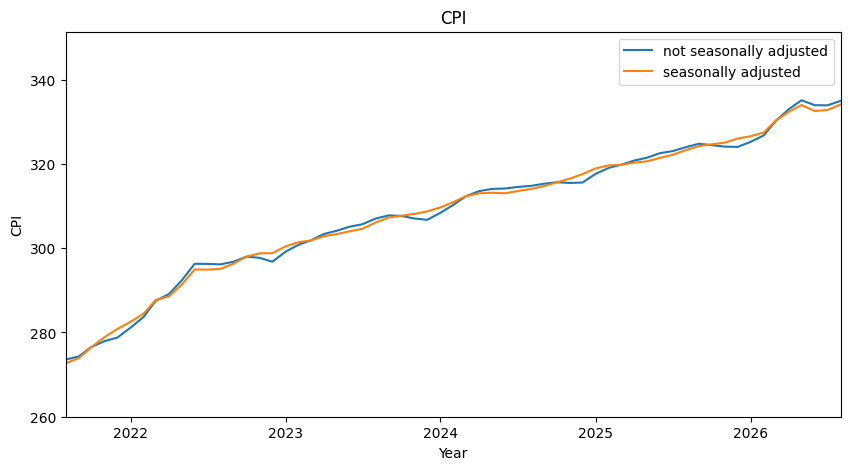

In [ ]:
# Seasonally adjusted vs unadjusted, last five years
cpi_nsa = load_fred("CPIAUCNS")
cpi_sa = load_fred("CPIAUCSL")
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(cpi_nsa.index, cpi_nsa,label= "not seasonally adjusted")
ax.plot(cpi_sa.index, cpi_sa,label= "seasonally adjusted")
ax.set_xlabel("Year")
ax.set_xlim(left=pd.Timestamp("2021-08-01"),right=pd.Timestamp("2026-08-01"))
ax.set_ylabel("CPI")
ax.set_ylim(bottom=260)
ax.set_title("CPI")
ax.legend()
plt.show()

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

*Your answer here.*
The gap consists of seasonal effects. The not seasonally adjusted series should be used because the price show how much the workers pay. But the gap is so small that you don't have to change the conclusion when you use the other series.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

Laspeyres index (2019 = 100): 129.78
Most weight-sensitive: Education (+0.37 index points per pp of weight)
Largest contributor:   Education (75.6% of the +29.78-point change)

                weight_pct  price_change_pct  index_excl_item  slope_pts_per_pp  contribution_pts  share_of_change_pct
Item                                                                                                                  
Education             45.0             50.00           113.23              0.37             22.50                75.57
Rent                  34.0              6.25           141.89             -0.36              2.12                 7.14
Internet               1.0             50.00           129.57              0.20              0.50                 1.68
Transportation         5.0             20.00           130.29             -0.10              1.00                 3.36
Clothese               2.0             20.00           129.97             -0.10              0.40            

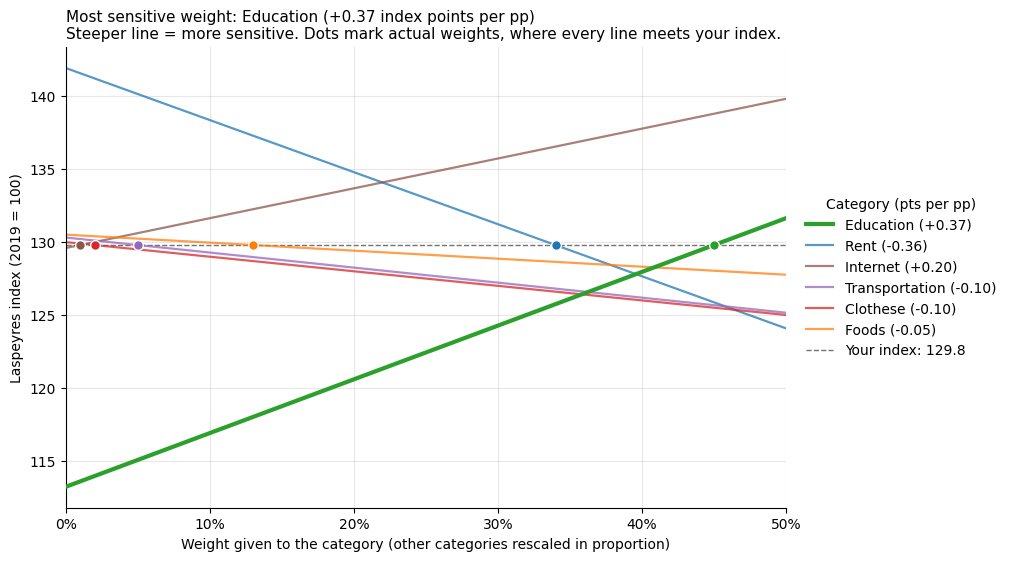

In [ ]:
# Paste the AI's code here, run it, and correct it where it is wrong

"""
Weight-sensitivity sweep for a weighted Laspeyres household price index.

Input
-----
household_basket : list of dicts with keys Item, Price_2019, Price_2024, weight
    `weight` is read as each category's 2019 (base-period) expenditure share,
    so the Laspeyres index is the share-weighted mean of the price relatives:
        index = 100 * sum(weight * Price_2024 / Price_2019)
    If your weights are quantities rather than shares, convert them first:
        weight = Price_2019 * quantity / sum(Price_2019 * quantity)
    Check that the base index printed by this script matches the one you have.

Method
------
For each category in turn, set its weight to every value from 0 to 0.5,
rescale the other categories so they keep their original proportions, and
recompute the index. All six sweeps go on one chart; the steepest line is the
category whose weight the result is most sensitive to.

Outputs: the chart, a printed summary, and laspeyres_weight_sensitivity.png,
_sweep.csv and _summary.csv in the working directory.

Run this where `household_basket` is already defined (e.g. the same notebook),
or import it at the top of this file. Needs numpy, pandas, matplotlib >= 3.5.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

SWEEP_MIN, SWEEP_MAX = 0.0, 0.5
SWEEP_STEPS = 51  # 1-percentage-point steps
OUTPUT_STEM = "laspeyres_weight_sensitivity"


def laspeyres_index(weights, price_relative):
    """Share-weighted Laspeyres index, 2019 = 100.

    `weights` is 1-D for one basket, or 2-D for one basket per row.
    """
    return 100.0 * np.asarray(weights) @ np.asarray(price_relative)


def prepare_basket(household_basket):
    """Validate household_basket and add each category's price relative."""
    basket = pd.DataFrame(household_basket)
    missing = {"Item", "Price_2019", "Price_2024", "weight"} - set(basket.columns)
    if missing:
        raise KeyError(f"household_basket is missing keys: {sorted(missing)}")
    if basket["Item"].duplicated().any():
        raise ValueError("Each Item must appear only once.")
    if (basket[["Price_2019", "Price_2024"]] <= 0).to_numpy().any():
        raise ValueError("Prices must be positive.")
    total_weight = basket["weight"].sum()
    if (basket["weight"] < 0).any() or total_weight <= 0:
        raise ValueError("Weights must be non-negative and not all zero.")
    if not np.isclose(total_weight, 1.0):
        print(f"Note: weights sum to {total_weight:.4f}; rescaled to sum to 1.")

    basket["weight"] = basket["weight"] / total_weight
    basket["price_relative"] = basket["Price_2024"] / basket["Price_2019"]
    return basket


def sweep_weights(basket, weight_grid):
    """Recompute the index as each category's weight runs over weight_grid.

    Returns a DataFrame: one row per swept weight, one column per Item.
    """
    weight = basket["weight"].to_numpy()
    price_relative = basket["price_relative"].to_numpy()
    sweeps = {}

    for k, item in enumerate(basket["Item"]):
        # Why the other weights must be renormalised
        # ------------------------------------------
        # Laspeyres weights are 2019 budget shares. They have to sum to 1 for
        # the index to mean "the cost of the 2019 basket at 2024 prices,
        # relative to 2019". If w_k were raised without lowering the others,
        # the sweep would add spending instead of reallocating it: the index
        # would rise by (extra weight x R_k) for every category, even one
        # whose price fell, so it would measure the size of the basket rather
        # than its mix.
        #
        # Rescaling the others by a common factor keeps their mix with each
        # other fixed, so the only thing that changes is how much category k
        # counts against everything else. That isolates one category per
        # sweep and makes the six sweeps comparable. The index becomes a
        # straight line in w:
        #     index(w) = 100 * (w * R_k + (1 - w) * R_rest)
        # where R_k is this category's price relative and R_rest is the
        # weighted price relative of the other categories. The slope,
        # R_k - R_rest, is how far this category's price change sits from
        # the rest of the basket; the value at w = 0 is the index excluding k.
        others = weight.copy()
        others[k] = 0.0
        if np.isclose(others.sum(), 0.0):
            raise ValueError(f"{item} holds all the weight; nothing to rescale.")
        others /= others.sum()                       # mix of the others, sums to 1

        swept = np.outer(1.0 - weight_grid, others)  # the others share 1 - w...
        swept[:, k] = weight_grid                    # ...after category k takes w
        assert np.allclose(swept.sum(axis=1), 1.0)
        sweeps[item] = laspeyres_index(swept, price_relative)

    return pd.DataFrame(sweeps, index=pd.Index(weight_grid, name="swept_weight"))


def summarise(basket, sweep):
    """One row per category, ordered from most to least weight-sensitive."""
    weight = basket["weight"].to_numpy()
    price_relative = basket["price_relative"].to_numpy()
    base_index = laspeyres_index(weight, price_relative)

    # Slope of each sweep line: index points per percentage point of weight.
    span_pp = 100 * (sweep.index[-1] - sweep.index[0])
    slope = (sweep.iloc[-1] - sweep.iloc[0]).to_numpy() / span_pp

    # Index excluding each category, and a check that the recomputed sweep
    # matches the closed form slope = R_k - R_rest from sweep_weights.
    index_excl_item = (base_index - 100 * weight * price_relative) / (1 - weight)
    assert np.allclose(slope, price_relative - index_excl_item / 100)

    # Contribution answers "what drove the change"; slope answers "which
    # weight, if wrong, moves the answer most". They can be different items.
    total_change = base_index - 100
    contribution = 100 * weight * (price_relative - 1)
    assert np.isclose(contribution.sum(), total_change)
    if np.isclose(total_change, 0.0):
        share_of_change = np.full_like(contribution, np.nan)
    else:
        share_of_change = 100 * contribution / total_change

    # What it would mean if the index were highly sensitive to one category
    # ----------------------------------------------------------------------
    # A steep line means the headline depends heavily on getting that one
    # weight right: an error of e percentage points shifts the index by
    # slope x e points. Because slope = R_k - R_rest, steepness comes from the
    # category's price change being far from the rest of the basket, not from
    # a large weight, so a small category with an unusual price change can
    # matter more than the largest one. It would mean that:
    #   - the result is largely a statement about one market, and should be
    #     reported with a range for that weight rather than a single point;
    #   - households whose spending on that category differs from the average
    #     (e.g. renters vs owners, if it is housing) have had materially
    #     different inflation from the headline;
    #   - the weight's source (survey year, sample, population covered) needs
    #     checking before the number goes to a client;
    #   - a fixed 2019 basket is least reliable there: the further one price
    #     diverges from the rest, the more households shift spending toward
    #     whatever became relatively cheaper, and the more a Laspeyres index
    #     overstates the rise in the cost of living.
    summary = pd.DataFrame(
        {
            "weight_pct": 100 * weight,
            "price_change_pct": 100 * (price_relative - 1),
            "index_excl_item": index_excl_item,
            "slope_pts_per_pp": slope,
            "contribution_pts": contribution,
            "share_of_change_pct": share_of_change,
        },
        index=pd.Index(basket["Item"], name="Item"),
    )
    order = summary["slope_pts_per_pp"].abs().sort_values(ascending=False).index
    return summary.loc[order], base_index


def plot_sensitivity(basket, sweep, summary, base_index):
    """Single chart: one line per category; the steepest is the most sensitive."""
    colours = {item: f"C{i}" for i, item in enumerate(basket["Item"])}
    actual_weight = basket.set_index("Item")["weight"]
    top_item = summary.index[0]
    top_slope = summary.at[top_item, "slope_pts_per_pp"]

    fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
    for item in summary.index:  # legend runs from most to least sensitive
        is_top = item == top_item
        ax.plot(
            sweep.index, sweep[item],
            color=colours[item],
            linewidth=3.0 if is_top else 1.6,
            alpha=1.0 if is_top else 0.75,
            zorder=3 if is_top else 2,
            label=f"{item} ({summary.at[item, 'slope_pts_per_pp']:+.2f})",
        )
        # Every line crosses the base index at the category's actual weight.
        if actual_weight[item] <= SWEEP_MAX:
            ax.plot(
                actual_weight[item], base_index,
                marker="o", linestyle="none", markersize=7,
                color=colours[item], markeredgecolor="white", zorder=4,
            )

    ax.axhline(base_index, color="0.45", linestyle="--", linewidth=1, zorder=1,
               label=f"Your index: {base_index:.1f}")
    ax.set_xlim(SWEEP_MIN, SWEEP_MAX)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
    ax.set_xlabel("Weight given to the category (other categories rescaled in proportion)")
    ax.set_ylabel("Laspeyres index (2019 = 100)")
    ax.set_title(
        f"Most sensitive weight: {top_item} ({top_slope:+.2f} index points per pp)\n"
        "Steeper line = more sensitive. Dots mark actual weights, "
        "where every line meets your index.",
        loc="left", fontsize=11,
    )
    ax.grid(True, alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(title="Category (pts per pp)", loc="center left",
              bbox_to_anchor=(1.01, 0.5), frameon=False)
    return fig, ax


def run_weight_sensitivity(household_basket, save_outputs=True):
    basket = prepare_basket(household_basket)
    weight_grid = np.linspace(SWEEP_MIN, SWEEP_MAX, SWEEP_STEPS)
    sweep = sweep_weights(basket, weight_grid)
    summary, base_index = summarise(basket, sweep)
    fig, _ = plot_sensitivity(basket, sweep, summary, base_index)

    top = summary.index[0]
    biggest = summary["contribution_pts"].abs().idxmax()
    print(f"Laspeyres index (2019 = 100): {base_index:.2f}")
    print(f"Most weight-sensitive: {top} "
          f"({summary.at[top, 'slope_pts_per_pp']:+.2f} index points per pp of weight)")
    print(f"Largest contributor:   {biggest} "
          f"({summary.at[biggest, 'share_of_change_pct']:.1f}% of the "
          f"{base_index - 100:+.2f}-point change)\n")
    print(summary.round(2).to_string())
    outside = summary.index[summary["weight_pct"] > 100 * SWEEP_MAX]
    if len(outside):
        print(f"\nNote: actual weight above {SWEEP_MAX:.0%} for {list(outside)}; "
              "its dot is off the chart.")

    if save_outputs:
        fig.savefig(f"{OUTPUT_STEM}.png", dpi=200, bbox_inches="tight")
        sweep.to_csv(f"{OUTPUT_STEM}_sweep.csv")
        summary.to_csv(f"{OUTPUT_STEM}_summary.csv")
    return basket, sweep, summary, fig


if __name__ == "__main__":
    basket, sweep, summary, fig = run_weight_sensitivity(household_basket)
    plt.show()

In [ ]:
# Check 1: AI's index at Education's actual weight (0.45) vs my own laspeyres()
my_index = laspeyres(household_basket, "Price_2019", "Price_2024")
ai_at_actual = sweep["Education"].iloc[45]   # row 45 = weight 0.45
print("My laspeyres():", my_index, "| AI sweep at 0.45:", ai_at_actual)

# Check 2: Education weight = 0, recomputed by hand
others = [item for item in household_basket if item["Item"] != "Education"]
total_w = sum(item["weight"] for item in others)
hand = 100 * sum(item["weight"] / total_w * item["Price_2024"] / item["Price_2019"] for item in others)
print("By hand, Education at 0:", hand, "| AI sweep at 0:", sweep["Education"].iloc[0])

My laspeyres(): 129.775 | AI sweep at 0.45: 129.775
By hand, Education at 0: 113.22727272727273 | AI sweep at 0: 113.22727272727272


**What did the model get wrong, or get right in a way you had to check? Show the check.**

*Your answer here.*
The model did not say which category dominates, because it did not have my data. Running the code showed Education: it causes 75.6% of the increase.

The model said it checked its results but did not show it, so I checked two numbers. At Education’s real weight, the AI and my laspeyres() both give 129.775. At weight 0, the AI and my hand calculation both give 113.227. The code is correct.

### AI Transcript

**Model:** &nbsp; claude opus 5.5 **Date:** 2026-10-09

*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*


```
[Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
[Evaluate] Tell me which category dominates my result and what I should say to a client about it.
```

I wrote the script as laspeyres_weight_sensitivity.py. Run it wherever `household_basket` already exists, either in the same notebook or by importing it at the top. It prints the base index, the most weight-sensitive category, the largest contributor and a ranked table. Then it draws the single chart and saves it, along with the sweep and the summary as CSVs.
I tested it under numpy 2.4, pandas 3.0 and matplotlib 3.10 with every warning treated as an error. It ran without warnings, and recomputing sweep points by hand matched the script. It treats `weight` as 2019 expenditure shares, so check that the printed base index matches yours. If it doesn't, your weights are probably quantities, and the docstring shows how to convert them.

**How the sensitivity works.** When the other weights are rescaled in proportion, the index is a straight line in the swept weight. Its slope is the gap between that category's price change and the price change of the rest of the basket. The script checks this formula against the recomputed sweep. So sensitivity comes from how different a category's price change is, not from how big its weight is. A large category that moved with the average gives a nearly flat line. A small one with an unusual price change can be the steepest.

**Which category dominates your result.** I can't tell you, because your message describes `household_basket` but doesn't include its values, and the answer depends entirely on them. The script's first printed lines will tell you. "Dominates" can mean two things, and they often point at different categories:
- **Largest contributor** (`share_of_change_pct`): which category drove the change.
- **Steepest line** (`slope_pts_per_pp`): which weight would move the answer most if it were wrong.

In one test basket I ran, a 55% rent share supplied two-thirds of the increase. The steepest line was a 5% phone category with falling prices.

**What to tell the client.** Fill this in from the table:

> The 2019 basket cost [X]% more at 2024 prices. [Contributor] accounts for [Y]% of the increase. The result is most sensitive to the [Category] weight: [Category] prices changed by [a]%, against [b]% for the rest of the basket, so each percentage point of budget share moves the index by [slope] points. For households whose [Category] share is 5 percentage points higher or lower, the index is between [I − 5×|slope|] and [I + 5×|slope|].

Then add one of two conclusions:
- **If that range is too small to change any decision,** say the result is robust to the weighting.
- **If it isn't,** say the headline depends on the [Category] weight. Report the range rather than a single number, and check that weight against the client's own households. Also note that a fixed 2019 basket ignores households switching toward items that got relatively cheaper. That makes it overstate the cost-of-living increase most where prices diverged most.

One caveat on the ranking: it assumes a percentage point of weight is equally uncertain for every category. If you expect errors to be proportional to the share, rank by slope × weight instead, which gives more weight to the large categories.

If you paste `household_basket` here, I'll run it and fill in the paragraph with your numbers.

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

*Your finding here.*
For the household we modelled, living costs rose about 30% from 2019 to 2024, while the official CPI rose about 21%. For this family, the CPI understates price growth rather than overstating it.

The result depends almost entirely on one item: private school fees. They make up 45% of this family’s spending, rose 50%, and account for about three-quarters of the increase. Without school fees, this family’s costs rose only about 13%, which is below the CPI.

So the answer to the client’s question depends on their workers. If their workers’ families pay large education costs, the CPI is too low for them. If they do not, the client may be right that the CPI is too high.

We are only moderately confident. The family and its prices are invented, and the official data are national averages rather than Boston prices. Changing the time period changes the long-run average inflation rate (3.5% a year since 1947 against 2.7% since 1989), but seasonal patterns and the missing October 2025 data do not affect the 2019–2024 comparison.

Recommendation: before the client decides on the starting wage, we should ask what share of their workers’ spending goes to education and housing.

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub